In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv", keep_default_na=False)
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns.tolist())
df.head()

(700, 16)
['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', 'Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Germany,Carretera,None,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
1,Government,Germany,Paseo,None,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014
2,Government,Canada,Paseo,None,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,1-Nov-13,11,November,2013
3,Government,Germany,Paseo,None,1513.0,10,350,529550.0,0.0,529550.0,393380.0,136170.0,1-Dec-14,12,December,2014
4,Government,Germany,Velo,None,1006.0,120,350,352100.0,0.0,352100.0,261560.0,90540.0,1-Jun-14,6,June,2014


In [2]:
print("Missing values:")
print(df.isna().sum().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
print("Discount Band counts:")
print(df["Discount Band"].value_counts())
print()
print("Loss-making rows:", (df["Profit"] < 0).sum())
print()
df.info()

Missing values:
0

Duplicate rows: 0

Discount Band counts:
Discount Band
High      245
Medium    242
Low       160
None       53
Name: count, dtype: int64

Loss-making rows: 58

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Segment              700 non-null    str    
 1   Country              700 non-null    str    
 2   Product              700 non-null    str    
 3   Discount Band        700 non-null    str    
 4   Units Sold           700 non-null    float64
 5   Manufacturing Price  700 non-null    int64  
 6   Sale Price           700 non-null    int64  
 7   Gross Sales          700 non-null    float64
 8   Discounts            700 non-null    float64
 9   Sales                700 non-null    float64
 10  COGS                 700 non-null    float64
 11  Profit               700 non-null    float64
 12  Date                 7

In [3]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%y")

df["Profit Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)
df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)
df["Loss Making"] = df["Profit"].lt(0).map({True: "Yes", False: "No"})

print(df["Date"].min().date(), "to", df["Date"].max().date())
print(df["Quarter"].value_counts().sort_index())
print(df.shape)
df.head(3)

2013-09-01 to 2014-12-01
Quarter
2013Q3     35
2013Q4    140
2014Q1    105
2014Q2    140
2014Q3    105
2014Q4    175
Name: count, dtype: int64
(700, 19)


,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year,Profit Margin %,Quarter,Loss Making
0,Government,Germany,Carretera,None,1513.0,3,350,529550.0,0.0,529550.0,393380.0,136170.0,2014-12-01,12,December,2014,25.71,2014Q4,No
1,Government,Germany,Paseo,None,1006.0,10,350,352100.0,0.0,352100.0,261560.0,90540.0,2014-06-01,6,June,2014,25.71,2014Q2,No
2,Government,Canada,Paseo,None,1725.0,10,350,603750.0,0.0,603750.0,448500.0,155250.0,2013-11-01,11,November,2013,25.71,2013Q4,No


In [4]:
df.to_csv("cleaned_sales_data.csv", index=False)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_units = df["Units Sold"].sum()

print("Total Sales: ", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Units: ", total_units)
print("Profit Margin %:", round(total_profit / total_sales * 100, 2))
print("Rows:", len(df))

Total Sales:  118726350.26
Total Profit: 16893702.26
Total Units:  1125806.0
Profit Margin %: 14.23
Rows: 700


In [5]:
seg = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Sales", "size")
)
seg["Margin %"] = (seg["Profit"] / seg["Sales"] * 100).round(1)
seg = seg.sort_values("Sales", ascending=False).round(0)
seg

,Sales,Profit,Orders,Margin %
Segment,,,,
Government,52504261.0,11388173.0,300,22.0
Small Business,42427918.0,4143168.0,100,10.0
Enterprise,19611694.0,-614546.0,100,-3.0
Midmarket,2381883.0,660103.0,100,28.0
Channel Partners,1800594.0,1316803.0,100,73.0


In [6]:
band = df.groupby("Discount Band").agg(
    Sales=("Sales", "sum"),
    Discounts=("Discounts", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Sales", "size")
)
band["Margin %"] = (band["Profit"] / band["Sales"] * 100).round(1)
band = band.reindex(["None", "Low", "Medium", "High"]).round(0)
band

,Sales,Discounts,Profit,Orders,Margin %
Discount Band,,,,,
None,7943654.0,0.0,1736455.0,53,22.0
Low,34629779.0,885676.0,6188858.0,160,18.0
Medium,38780431.0,3002546.0,5579523.0,242,14.0
High,37372487.0,5317026.0,3388867.0,245,9.0


In [7]:
losses = df[df["Profit"] < 0]

print("Loss-making orders:", len(losses))
print("Total loss:", round(losses["Profit"].sum(), 2))
print()
print(losses.groupby(["Segment", "Discount Band"]).size())

Loss-making orders: 58
Total loss: -777321.25

Segment     Discount Band
Enterprise  High             33
            Medium           25
dtype: int64


In [8]:
def summarise(column):
    t = df.groupby(column).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Sales", "size")
    )
    t["Margin %"] = (t["Profit"] / t["Sales"] * 100).round(1)
    return t.sort_values("Sales", ascending=False).round(0)

print(summarise("Product"))
print()
print(summarise("Country"))

                Sales     Profit  Orders  Margin %
Product                                           
Paseo      33011144.0  4797438.0     202      14.0
VTT        20511921.0  3034608.0     109      15.0
Velo       18250059.0  2305992.0     109      13.0
Amarilla   17747116.0  2814104.0      94      16.0
Montana    15390802.0  2114755.0      93      14.0
Carretera  13815308.0  1826805.0      93      13.0

                               Sales     Profit  Orders  Margin %
Country                                                          
United States of America  25029830.0  2995541.0     140      12.0
Canada                    24887655.0  3529229.0     140      14.0
France                    24354172.0  3781021.0     140      16.0
Germany                   23505341.0  3680389.0     140      16.0
Mexico                    20949352.0  2907523.0     140      14.0


In [9]:
q = df.groupby("Quarter").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Sales", "size")
)
q["Margin %"] = (q["Profit"] / q["Sales"] * 100).round(1)
q.round(0)

,Sales,Profit,Orders,Margin %
Quarter,,,,
2013Q3,4484000.0,763603.0,35,17.0
2013Q4,21931255.0,3114861.0,140,14.0
2014Q1,19492153.0,2632443.0,105,14.0
2014Q2,22693880.0,3232378.0,140,14.0
2014Q3,20366240.0,2738064.0,105,13.0
2014Q4,29758822.0,4412352.0,175,15.0


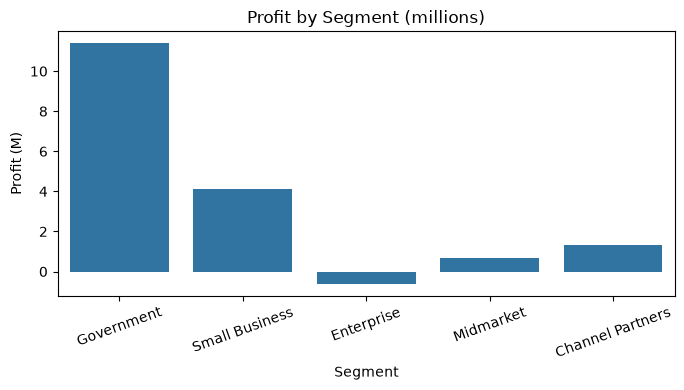

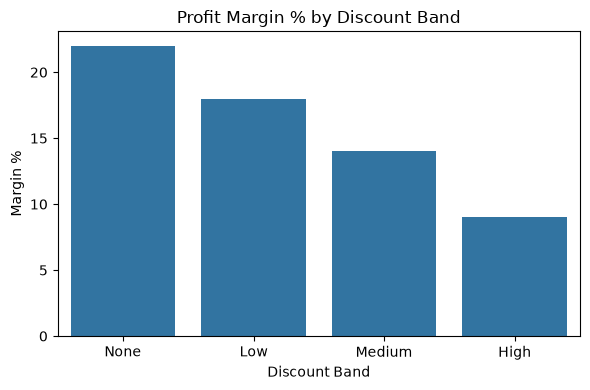

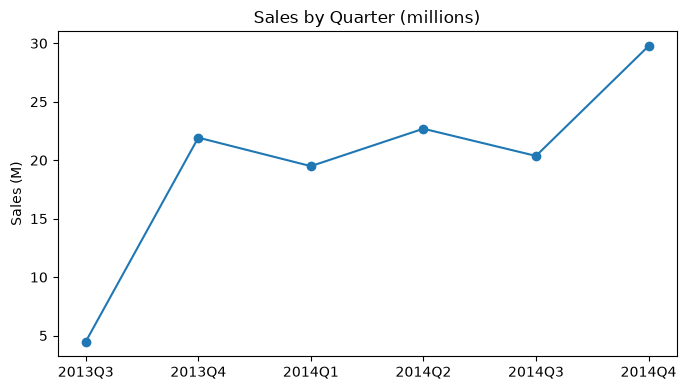

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

s = seg.reset_index()
s["Profit (M)"] = s["Profit"] / 1e6
plt.figure(figsize=(7, 4))
sns.barplot(data=s, x="Segment", y="Profit (M)")
plt.title("Profit by Segment (millions)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("profit_by_segment.png")
plt.show()

b = band.reset_index()
plt.figure(figsize=(6, 4))
sns.barplot(data=b, x="Discount Band", y="Margin %")
plt.title("Profit Margin % by Discount Band")
plt.tight_layout()
plt.savefig("margin_by_discount.png")
plt.show()

qq = q.reset_index()
qq["Sales (M)"] = qq["Sales"] / 1e6
plt.figure(figsize=(7, 4))
plt.plot(qq["Quarter"], qq["Sales (M)"], marker="o")
plt.title("Sales by Quarter (millions)")
plt.ylabel("Sales (M)")
plt.tight_layout()
plt.savefig("sales_by_quarter.png")
plt.show()